# Autoencoder on NF-CICIDS2018, replayed day by day

Same replay as `02_drift_cicids2018.ipynb`, with an anomaly detector instead of the Random Forest.
The autoencoder only learns to reconstruct **benign** traffic; a flow it reconstructs badly is flagged as an
attack. It needs no attack label, so it can in principle flag attack families it has never seen.

- **frozen**: trained by `train@autoencoder` on the benign flows of the UNSW training data, deployed as is on the
  NF-CICIDS2018 network and never updated;
- **retrained**: retrained every night on the benign UNSW flows plus the benign flows of all previous CIC days
  (known once the labels of a day arrive, the next day).

The threshold is set so that 1 % of the held-out benign flows of the training data are flagged, and it is
recomputed at each retraining. The model is defined in `src/models/autoencoder.py` (settings under
`train.autoencoder` in `params.yaml`) and replayed by the DVC stage `drift@autoencoder`. This notebook only reads
`evaluation/autoencoder/drift/` and plots it. Run `dvc pull` then `dvc repro` first.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with open(ROOT / "params.yaml") as f:
    FP_TARGET = yaml.safe_load(f)["train"]["autoencoder"]["false_positive_target"]

def read(model):
    out = ROOT / "evaluation" / model / "drift"
    with open(out / "summary.json") as f:
        summary = json.load(f)
    return (pd.read_csv(out / "days.csv", parse_dates=["day"]),
            pd.read_csv(out / "families.csv", parse_dates=["day"]), summary)

results, families, summary = read("autoencoder")
rf, _, rf_summary = read("random_forest")

PERCENT = FuncFormatter(lambda v, _: f"{v:g} %")  # axis ticks as percentages
labels = [f"{d:%d %b}\n{a}" for d, a in zip(results["day"], results["attacks"])]
x = np.arange(len(results))
print(json.dumps(summary, indent=2))

{
  "days": 10,
  "frozen": {
    "mean_mcc": 0.10154181209014088,
    "mean_false_positive_%": 86.27005493190474
  },
  "retrained": {
    "mean_mcc": 0.2915859396902915,
    "mean_mcc_new_family_days": 0.33359384044137647,
    "mean_false_positive_%": 1.2967727371622064
  },
  "psi_vs_previous_day": {
    "new_family_days": 7,
    "alerts_on_new_family_days": 3,
    "alerts_on_control_days": 0
  }
}


## 1. Detection per day

MCC as main metric (1 = perfect, 0 = no better than chance, undefined on 23 Feb without attack), recall and false
positive rate to explain it. The AUC measures whether attacks get a higher score than benign flows, whatever the
threshold; an IDS works at a low false positive rate, so the MCC at the threshold is what matters.

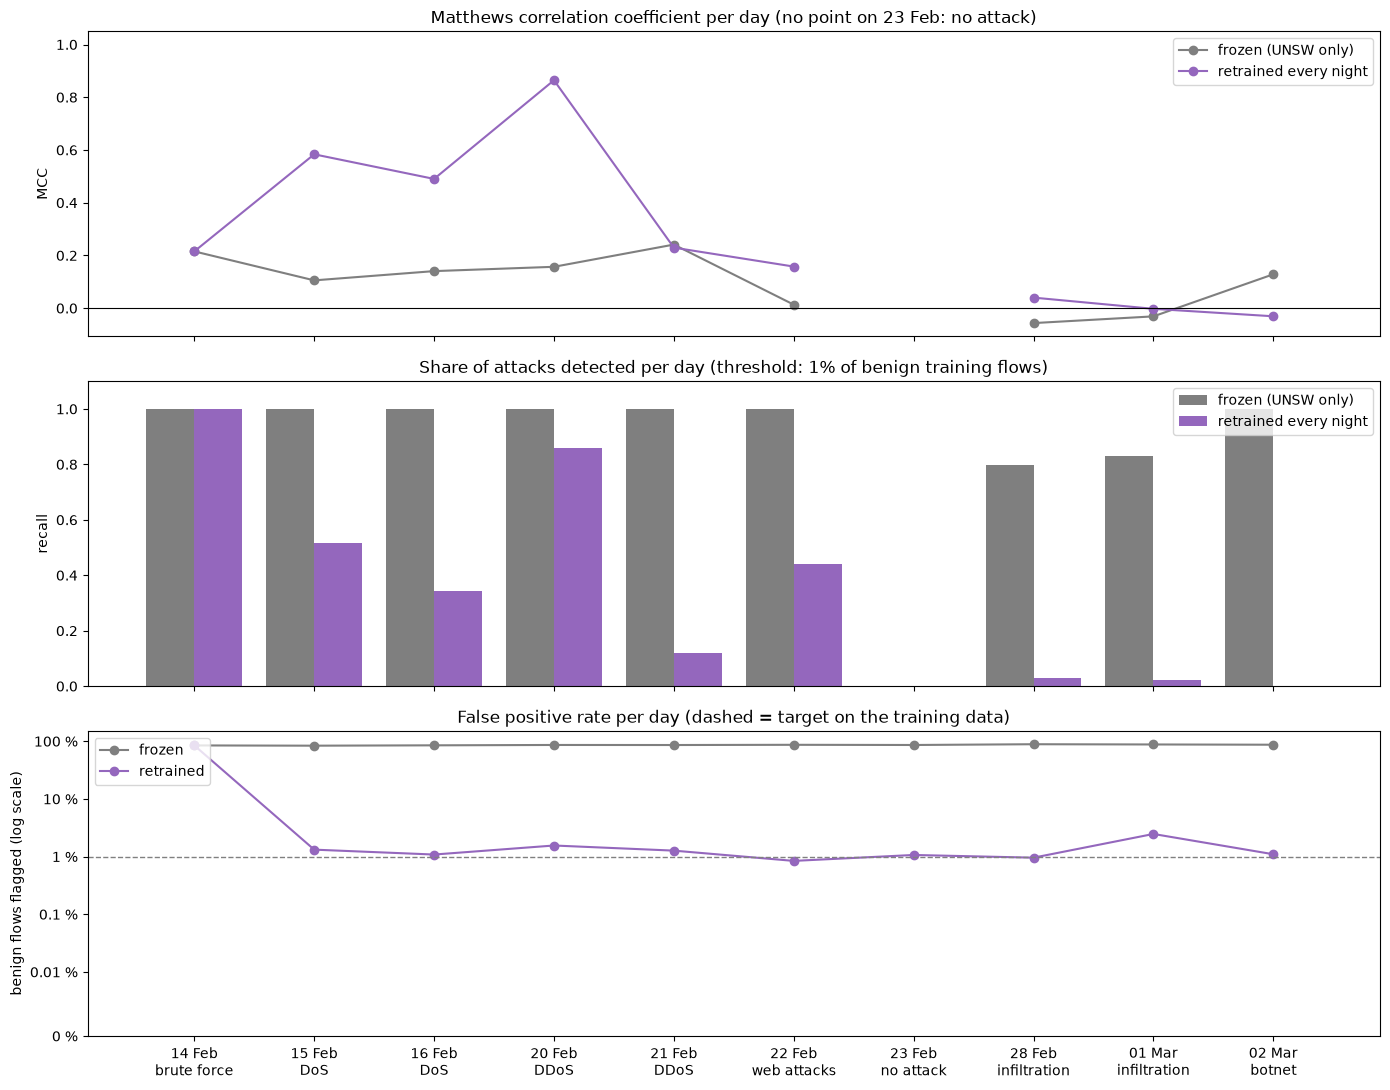

,day,attacks,frozen_mcc,frozen_false_positive_%,retrained_recall,retrained_false_positive_%,retrained_mcc,retrained_auc
0,14 Feb,brute force,0.215,84.681,1.000,84.681,0.215,0.437
1,15 Feb,DoS,0.105,83.822,0.516,1.321,0.584,0.983
2,16 Feb,DoS,0.141,85.009,0.343,1.086,0.490,0.987
3,20 Feb,DDoS,0.157,86.248,0.859,1.558,0.865,0.987
4,21 Feb,DDoS,0.241,86.053,0.119,1.270,0.230,0.916
5,22 Feb,web attacks,0.013,86.803,0.442,0.843,0.158,0.969
6,23 Feb,no attack,NaN,86.164,NaN,1.067,NaN,NaN
7,28 Feb,infiltration,-0.057,88.829,0.030,0.958,0.040,0.488
8,01 Mar,infiltration,-0.031,87.983,0.023,2.469,-0.002,0.578
9,02 Mar,botnet,0.129,87.108,0.001,1.099,-0.031,0.883


In [2]:
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
mcc_cols = ["frozen_mcc", "retrained_mcc"]
ax0.plot(x, results["frozen_mcc"], "o-", color="tab:grey", label="frozen (UNSW only)")
ax0.plot(x, results["retrained_mcc"], "o-", color="tab:purple", label="retrained every night")
ax0.axhline(0, color="black", lw=0.8)
ax0.set_ylim(min(0, results[mcc_cols].min().min()) - 0.05, 1.05)
ax0.set_ylabel("MCC")
ax0.set_title("Matthews correlation coefficient per day (no point on 23 Feb: no attack)")
ax0.legend(loc="upper right")
ax1.bar(x - 0.2, results["frozen_recall"], 0.4, label="frozen (UNSW only)", color="tab:grey")
ax1.bar(x + 0.2, results["retrained_recall"], 0.4, label="retrained every night", color="tab:purple")
ax1.set_ylim(0, 1.1)
ax1.set_ylabel("recall")
ax1.set_title(f"Share of attacks detected per day (threshold: {FP_TARGET:.0%} of benign training flows)")
ax1.legend(loc="upper right")

ax2.plot(x, results["frozen_false_positive_%"], "o-", color="tab:grey", label="frozen")
ax2.plot(x, results["retrained_false_positive_%"], "o-", color="tab:purple", label="retrained")
ax2.axhline(100 * FP_TARGET, ls="--", color="grey", lw=1)
ax2.set_yscale("symlog", linthresh=0.01)
ax2.set_ylim(0, 150)
ax2.yaxis.set_major_formatter(PERCENT)
ax2.set_ylabel("benign flows flagged (log scale)")
ax2.set_title("False positive rate per day (dashed = target on the training data)")
ax2.set_xticks(x, labels)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

results[["day", "attacks", "frozen_mcc", "frozen_false_positive_%", "retrained_recall",
         "retrained_false_positive_%", "retrained_mcc", "retrained_auc"]].assign(
    day=results["day"].dt.strftime("%d %b")).round(3)

In [3]:
# Recall per attack family
families.assign(day=families["day"].dt.strftime("%d %b")).round(3)

,day,family,flows,recall_frozen,recall_retrained
0,14 Feb,FTP brute force,77300,1.000,1.000
1,14 Feb,SSH brute force,37721,1.000,1.000
2,15 Feb,DoS GoldenEye,12209,1.000,0.310
3,15 Feb,DoS Slowloris,7233,1.000,0.862
4,16 Feb,DoS Hulk,19898,1.000,0.703
5,16 Feb,DoS SlowHTTPTest,20907,1.000,0.000
6,20 Feb,DDoS LOIC-HTTP,57903,1.000,0.859
7,21 Feb,DDoS HOIC,206489,1.000,0.116
8,21 Feb,DDoS LOIC-UDP,670,1.000,1.000
9,22 Feb,SQL injection,80,1.000,0.862


## 2. Drift signal without labels

The share of flows above the threshold is known right away. On benign traffic like the training data it
should stay close to 1 %: more means that something new is in the traffic (new attacks, or benign traffic that
changed). Here a drift alert is raised when it exceeds twice the target. 23 Feb has no attack.

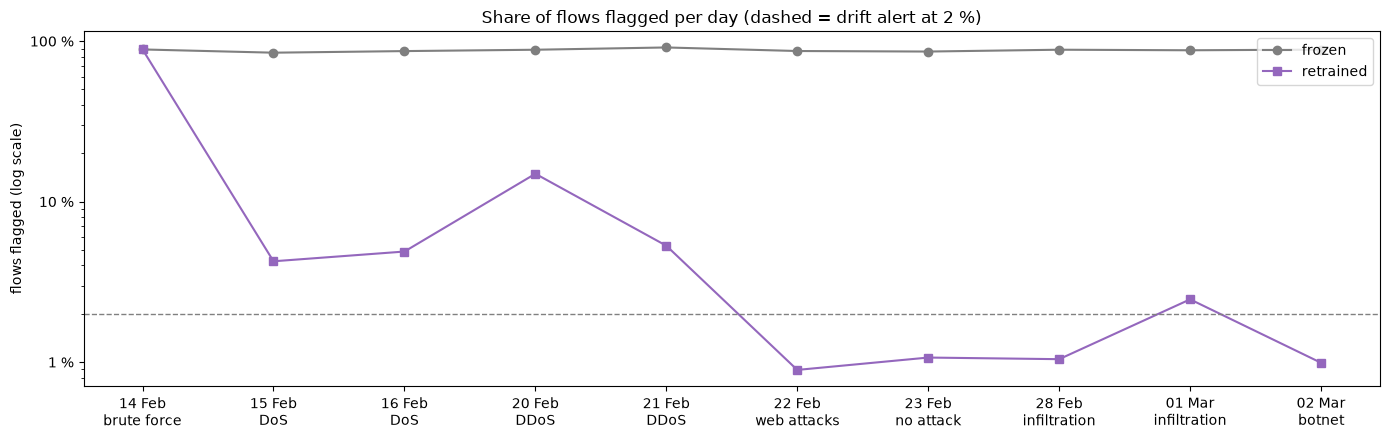

,day,new_family,frozen_flagged_%,frozen_alert,retrained_flagged_%,retrained_alert
0,14 Feb,True,88.80,True,88.80,True
1,15 Feb,True,84.77,True,4.25,True
2,16 Feb,True,86.72,True,4.89,True
3,20 Feb,True,88.43,True,14.92,True
4,21 Feb,True,91.37,True,5.31,True
5,22 Feb,True,86.82,True,0.89,False
6,23 Feb,False,86.16,True,1.07,False
7,28 Feb,True,88.45,True,1.04,False
8,01 Mar,False,87.76,True,2.46,True
9,02 Mar,True,88.57,True,0.99,False


In [4]:
ALERT = 2 * 100 * FP_TARGET
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(x, results["frozen_flagged_%"], "o-", color="tab:grey", label="frozen")
ax.plot(x, results["retrained_flagged_%"], "s-", color="tab:purple", label="retrained")
ax.axhline(ALERT, ls="--", color="grey", lw=1)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(PERCENT)
ax.set_ylabel("flows flagged (log scale)")
ax.set_title(f"Share of flows flagged per day (dashed = drift alert at {ALERT:.0f} %)")
ax.set_xticks(x, labels)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame({"day": results["day"].dt.strftime("%d %b"), "new_family": results["new_family"],
              "frozen_flagged_%": results["frozen_flagged_%"], "frozen_alert": results["frozen_flagged_%"] > ALERT,
              "retrained_flagged_%": results["retrained_flagged_%"],
              "retrained_alert": results["retrained_flagged_%"] > ALERT}).round(2)

## 3. Compared with the Random Forest (notebook 02)

Both replays come from the same pipeline (`drift@random_forest` and `drift@autoencoder`), on the same sample.
`dvc metrics show` gives the same comparison for the summaries.

In [5]:
comparison = pd.DataFrame({
    "day": results["day"].dt.strftime("%d %b"),
    "attacks": results["attacks"],
    "RF frozen MCC": rf["frozen_mcc"].to_numpy(),
    "AE frozen MCC": results["frozen_mcc"].to_numpy(),
    "RF retrained MCC": rf["retrained_mcc"].to_numpy(),
    "AE retrained MCC": results["retrained_mcc"].to_numpy(),
    "RF retrained recall": rf["retrained_recall"].to_numpy(),
    "AE retrained recall": results["retrained_recall"].to_numpy(),
    "RF retrained FP %": rf["retrained_false_positive_%"].to_numpy(),
    "AE retrained FP %": results["retrained_false_positive_%"].to_numpy(),
})
display(comparison.round(3))
pd.DataFrame({"Random Forest": pd.json_normalize(rf_summary).iloc[0],
              "Autoencoder": pd.json_normalize(summary).iloc[0]}).round(3)

,day,attacks,RF frozen MCC,AE frozen MCC,RF retrained MCC,AE retrained MCC,RF retrained recall,AE retrained recall,RF retrained FP %,AE retrained FP %
0,14 Feb,brute force,0.045,0.215,0.045,0.215,0.672,1.000,62.291,84.681
1,15 Feb,DoS,-0.177,0.105,-0.000,0.584,0.000,0.516,0.000,1.321
2,16 Feb,DoS,-0.054,0.141,0.749,0.490,0.590,0.343,0.002,1.086
3,20 Feb,DDoS,0.272,0.157,0.013,0.865,0.001,0.859,0.013,1.558
4,21 Feb,DDoS,0.406,0.241,0.041,0.230,0.003,0.119,0.014,1.270
5,22 Feb,web attacks,0.022,0.013,-0.000,0.158,0.000,0.442,0.001,0.843
6,23 Feb,no attack,NaN,NaN,NaN,NaN,NaN,NaN,0.010,1.067
7,28 Feb,infiltration,-0.103,-0.057,-0.003,0.040,0.000,0.030,0.047,0.958
8,01 Mar,infiltration,-0.050,-0.031,0.588,-0.002,0.373,0.023,0.082,2.469
9,02 Mar,botnet,0.218,0.129,-0.011,-0.031,0.000,0.001,0.101,1.099


,Random Forest,Autoencoder
days,10.000,10.000
frozen.mean_mcc,0.064,0.102
frozen.mean_false_positive_%,66.601,86.270
retrained.mean_mcc,0.172,0.292
retrained.mean_mcc_new_family_days,0.113,0.334
retrained.mean_false_positive_%,0.030,1.297
psi_vs_previous_day.new_family_days,7.000,7.000
psi_vs_previous_day.alerts_on_new_family_days,3.000,3.000
psi_vs_previous_day.alerts_on_control_days,0.000,0.000


## What this shows

- Trained on benign UNSW traffic, the autoencoder flags 84 to 89 % of the benign CIC flows (MCC 0.24 at best): for
  it, the whole new network is an anomaly.
- Retrained every night on benign UNSW plus the benign flows of the previous CIC days, it flags about 1 % of the
  benign flows (0.8 % to 2.5 %) and, without any attack label, reaches an MCC of 0.58 (15 Feb, DoS), 0.49 (16 Feb,
  DoS), 0.86 (20 Feb, DDoS LOIC-HTTP), 0.23 (21 Feb, DDoS) and 0.16 (22 Feb, web attacks) on the day these families
  appear. On the same days the retrained Random Forest is close to 0, except on 16 Feb (0.75). Mean MCC on the days a
  new family appears: 0.33 for the autoencoder, 0.11 for the Random Forest.
- Recall per family: XSS 92 %, DDoS LOIC-HTTP 86 %, DoS Slowloris 86 %, SQL injection 86 %, DoS Hulk 70 %, DDoS
  LOIC-UDP 100 %, DoS GoldenEye 31 %, web brute force 19 %, DDoS HOIC 12 %.
- It stays blind to DoS SlowHTTPTest, infiltration (AUC about 0.5: these flows look like benign traffic) and
  botnet: MCC about 0 on 28 Feb, 1 Mar and 2 Mar. Botnet flows do score higher than benign ones (AUC 0.88), but
  stay under the threshold.
- The cost: about 1 % of the benign flows flagged every day, against 0.0003 % to 0.1 % for the retrained Random
  Forest.
- As a drift signal without labels (share of flagged flows above 2 %), the retrained autoencoder fires on 15, 16, 20
  and 21 Feb and stays quiet on the control day (23 Feb), but misses 22 and 28 Feb and 2 Mar, and fires on 1 Mar when
  mostly benign flows are flagged.

So the two models complement each other: the Random Forest is best when an attack was already seen (16 Feb, 1 Mar)
and raises almost no false alarm; the autoencoder catches part of the new families on the day they appear (15, 20,
21 and 22 Feb), at the cost of about 1 % false alarms.